<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME_640_13_Heuristic_Optimization_GA_DE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ME 640 — Heuristic Optimization for Mechanical Design
## Genetic Algorithms and Differential Evolution

This module introduces population-based heuristic optimization through mechanical-vibration design examples. The three cases are deliberately progressive:

1. **Unconstrained forced-vibration tuning** — multimodality and initialization.
2. **Constrained vibration-isolator design** — feasibility and penalty methods.
3. **Multiobjective vibration-isolator design** — Pareto tradeoffs.

For every problem, the same three solution families are compared: a gradient-based local method, a real-coded **Genetic Algorithm (GA)**, and **Differential Evolution (DE)**.

### Learning objectives
- Explain local versus population-based search.
- Implement GA selection, crossover, mutation, and elitism.
- Implement DE/rand/1/bin mutation, crossover, and greedy selection.
- Handle constraints explicitly and with penalties.
- Compare algorithms using objective quality, feasibility, evaluations, and repeatability.
- Construct an approximate Pareto front by repeated scalarization.

### Core references
- Holland, J. H. (1975), [*Adaptation in Natural and Artificial Systems*](http://echo.louisville.edu/login?url=https://www.proquest.com/scholarly-journals/adaptation-natural-artificial-systems-john-h/docview/926190985/se-2?accountid=14665).
- Goldberg, D. E. (1994), [*Genetic and evolutionary algorithms come of age*](https://go.gale.com/ps/anonymous?id=GALE%7CA15061357&sid=googleScholar&v=2.1&it=r&linkaccess=abs&issn=00010782&p=AONE&sw=w)
- Storn, R. & Price, K. (1997), [*“Differential Evolution — A Simple and Efficient Heuristic for Global Optimization over Continuous Spaces"*](https://doi.org/10.1023/A:1008202821328), *Journal of Global Optimization*, 11, 341–359

The vibration cases below are instructional problems constructed from standard SDOF vibration relations; they are not presented as published benchmark problems.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
np.random.seed(640)
plt.rcParams["figure.figsize"]=(7.5,5.0)
plt.rcParams["font.size"]=10.5

def penalty_value(g,rho=1e6):
    g=np.asarray(g,float)
    return rho*np.sum(np.maximum(g,0.0)**2)

def nondominated_mask(F):
    F=np.asarray(F)
    keep=np.ones(len(F),dtype=bool)
    for i in range(len(F)):
        if np.any(np.all(F<=F[i],axis=1)&np.any(F<F[i],axis=1)):
            keep[i]=False
    return keep

# 1. Algorithm foundations

## 1.1 Gradient-based optimization
For a smooth problem $\min f(\mathbf x)$, local methods exploit derivative/local-model information to generate a direction $\mathbf p_k$ and update $\mathbf x_{k+1}=\mathbf x_k+\alpha_k\mathbf p_k$. They can be highly efficient, but the result can depend on the initial point when multiple local minima exist.

## 1.2 Genetic Algorithm
A real-coded GA evolves a population through

$$
\boxed{\text{initialize}\to\text{evaluate}\to\text{select}\to\text{crossover}\to\text{mutate}\to\text{elitism}\to\text{repeat}}.
$$

**Tournament selection:** sample several candidates and retain the best.  
**Arithmetic crossover:**
$$
\mathbf c_1=\alpha\mathbf p_1+(1-\alpha)\mathbf p_2,
\qquad
\mathbf c_2=\alpha\mathbf p_2+(1-\alpha)\mathbf p_1.
$$
**Gaussian mutation:** $x'_j=x_j+\sigma_jN(0,1)$.  
**Elitism:** preserve one or more best individuals.

## 1.3 Differential Evolution
For DE/rand/1/bin, choose distinct population vectors and form
$$
\boxed{\mathbf v_i=\mathbf x_{r_1}+F(\mathbf x_{r_2}-\mathbf x_{r_3})}.
$$
Binomial crossover mixes mutant and target components with crossover probability $CR$. Greedy selection retains the trial vector only when it is at least as good as the target.

## 1.4 Constraint handling
For constraints $g_j(\mathbf x)\le0$, a simple exterior penalty is
$$
F_p(\mathbf x)=f(\mathbf x)+\rho\sum_j\max(0,g_j)^2.
$$
The penalty coefficient changes the search landscape and must be checked rather than treated as an arbitrary constant.

## 1.5 Fair comparison
A stochastic algorithm should be run with several seeds. A local algorithm should be tested from several starting points when multimodality is plausible. Function-evaluation count is especially important when each objective call represents an experiment, FEA, CFD, or another expensive simulation.

## 1.6 Complete teaching implementation of a real-coded GA
The implementation below deliberately exposes every major operator rather than relying on a black-box package.

In [2]:
def genetic_algorithm(objective,bounds,constraints=None,pop_size=60,generations=120,
                      crossover_rate=.90,mutation_rate=.15,mutation_scale=.08,
                      tournament_size=3,elite=2,rho=1e6,seed=1):
    rng=np.random.default_rng(seed); n=len(bounds)
    lo=np.array([b[0] for b in bounds],float); hi=np.array([b[1] for b in bounds],float); span=hi-lo
    pop=rng.uniform(lo,hi,size=(pop_size,n)); nfev=0; history=[]
    def fitness(x):
        nonlocal nfev
        nfev+=1; v=objective(x)
        if constraints is not None: v+=penalty_value(constraints(x),rho)
        return v
    fit=np.array([fitness(x) for x in pop])
    for generation in range(generations):
        def tournament():
            ids=rng.choice(pop_size,size=tournament_size,replace=False)
            return pop[ids[np.argmin(fit[ids])]].copy()
        order=np.argsort(fit); new=[pop[i].copy() for i in order[:elite]]
        while len(new)<pop_size:
            p1,p2=tournament(),tournament()
            if rng.random()<crossover_rate:
                a=rng.random(n); c1=a*p1+(1-a)*p2; c2=a*p2+(1-a)*p1
            else: c1,c2=p1.copy(),p2.copy()
            for child in (c1,c2):
                mask=rng.random(n)<mutation_rate
                child[mask]+=rng.normal(0,mutation_scale*span[mask])
                child[:]=np.clip(child,lo,hi); new.append(child.copy())
                if len(new)>=pop_size: break
        pop=np.asarray(new[:pop_size]); fit=np.array([fitness(x) for x in pop]); history.append(fit.min())
    i=np.argmin(fit)
    return {'x':pop[i].copy(),'fun':float(objective(pop[i])),'penalized':float(fit[i]),'nfev':nfev,'history':np.array(history)}

## 1.7 Complete teaching implementation of DE/rand/1/bin
This implementation similarly exposes mutation, binomial crossover, and greedy selection.

In [3]:
def differential_evolution_manual(objective,bounds,constraints=None,pop_size=60,generations=120,
                                  F=.7,CR=.9,rho=1e6,seed=1):
    rng=np.random.default_rng(seed); n=len(bounds)
    lo=np.array([b[0] for b in bounds],float); hi=np.array([b[1] for b in bounds],float)
    pop=rng.uniform(lo,hi,size=(pop_size,n)); nfev=0; history=[]
    def fitness(x):
        nonlocal nfev
        nfev+=1; v=objective(x)
        if constraints is not None: v+=penalty_value(constraints(x),rho)
        return v
    fit=np.array([fitness(x) for x in pop])
    for generation in range(generations):
        for i in range(pop_size):
            ids=np.delete(np.arange(pop_size),i); r1,r2,r3=rng.choice(ids,3,replace=False)
            mutant=np.clip(pop[r1]+F*(pop[r2]-pop[r3]),lo,hi)
            mask=rng.random(n)<CR; mask[rng.integers(n)]=True
            trial=np.where(mask,mutant,pop[i]); ft=fitness(trial)
            if ft<=fit[i]: pop[i]=trial; fit[i]=ft
        history.append(fit.min())
    i=np.argmin(fit)
    return {'x':pop[i].copy(),'fun':float(objective(pop[i])),'penalized':float(fit[i]),'nfev':nfev,'history':np.array(history)}

# 2. Problem 1 — Unconstrained forced-vibration tuning
Consider
$$
m\ddot x+c\dot x+kx=F_0\sin\omega t,
$$
with steady-state amplitude
$$
X(k,c;\omega)=\frac{F_0}{\sqrt{(k-m\omega^2)^2+(c\omega)^2}}.
$$
A machine operates near three frequencies, $\Omega=[22,32,42]$ rad/s. Define
$$
J(k,c)=\sum_iw_i\left(\frac{X(k,c;\omega_i)}{0.02}\right)^2+0.35\left(\frac{c}{800}\right)^2,
$$
where $w=[1.0,1.2,0.8]$, $m=20$ kg, and $F_0=100$ N.

Design variables and bounds:
$$
8000\le k\le45000\ \mathrm{N/m},\qquad20\le c\le800\ \mathrm{N\,s/m}.
$$

The multiple operating frequencies create several resonance-related regions in the objective landscape. The damping penalty prevents the trivial choice of maximum damping.

## Tasks
1. Implement the amplitude and objective.
2. Plot the objective landscape.
3. Run L-BFGS-B from at least five starts.
4. Run GA and DE with comparable budgets.
5. Plot convergence histories.
6. Repeat GA/DE with at least five seeds.
7. Explain differences in objective quality and evaluation cost.

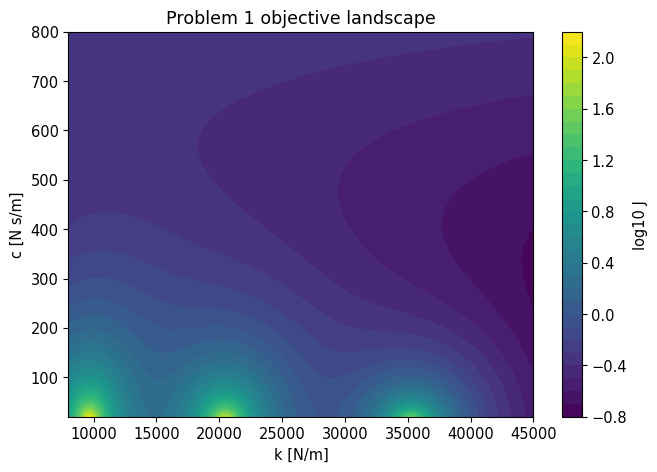

In [17]:
m1,F01=20.,100.; omegas1=np.array([22.,32.,42.]); weights1=np.array([1.,1.2,.8]); bounds1=[(8000.,45000.),(20.,800.)]

def amplitude_sdof(k,c,omega):
    return F01 / np.sqrt((k - m1 * omega**2)**2 + (c * omega)**2)

def objective1(x):
    k, c = x
    terms = np.array([amplitude_sdof(k, c, w) for w in omegas1])
    return np.sum(weights1 * (terms / 0.02)**2) + 0.35 * (c / 800.0)**2

# 1. Contours
K = np.linspace(8000, 45000, 160)
Cc = np.linspace(20, 800, 120)
KK, CC = np.meshgrid(K, Cc)
ZZ = np.array([[objective1([k, c]) for k in K] for c in Cc])

fig, ax = plt.subplots()
cs = ax.contourf(KK, CC, np.log10(ZZ), 30)
fig.colorbar(cs, ax=ax, label='log10 J')
ax.set(xlabel='k [N/m]', ylabel='c [N s/m]', title='Problem 1 objective landscape')
plt.show()

## 2.1 Gradient-based solution — multistart L-BFGS-B
Because the problem is box-bounded and smooth, L-BFGS-B is appropriate. Multiple starts reveal whether different basins are encountered.

In [18]:
# 2. Multistart L-BFGS-B
starts = [[10000, 100], [18000, 300], [26000, 500], [36000, 250], [43000, 700]]
rows = []
for x0 in starts:
    r = minimize(objective1, x0, method='L-BFGS-B', bounds=bounds1, options={'maxiter': 1000, 'ftol': 1e-12})
    rows.append([*x0, *r.x, r.fun, r.nfev, r.success])
local1 = pd.DataFrame(rows, columns=['k0', 'c0', 'k*', 'c*', 'J*', 'nfev', 'success'])
display(local1.round(5))
bestlocal1 = local1.loc[local1['J*'].idxmin()]

,k0,c0,k*,c*,J*,nfev,success
0,10000,100,9991.63436,601.52970,0.41864,39,True
1,18000,300,17948.60102,570.87259,0.39985,21,True
2,26000,500,26004.60730,510.10655,0.34372,36,True
3,36000,250,35983.71316,421.90209,0.26405,21,True
4,43000,700,43124.63546,349.74306,0.20726,21,True


## 2.2 GA solution
The GA searches the complete box with a population rather than a single initial point.

GA: [45000.           317.01411626] J= 0.19044817004405823 nfev= 9870


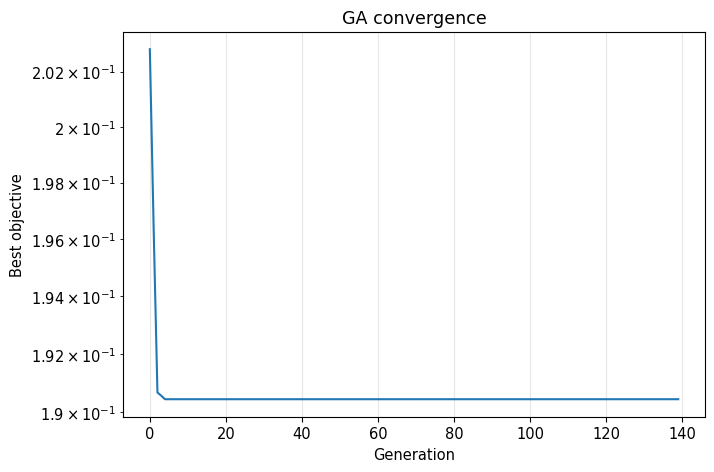

In [20]:
# 3. GA
ga1 = genetic_algorithm(objective1, bounds1, pop_size=70, generations=140, mutation_rate=.18, mutation_scale=.06, seed=11)
print('GA:',ga1['x'],'J=',ga1['fun'],'nfev=',ga1['nfev']);

plt.plot(ga1['history']);
plt.yscale('log');
plt.xlabel('Generation');
plt.ylabel('Best objective');
plt.title('GA convergence');
plt.grid(alpha=.3);
plt.show()

## 2.3 DE solution

DE: [45000.           317.01411798] J= 0.19044817004405823 nfev= 9870


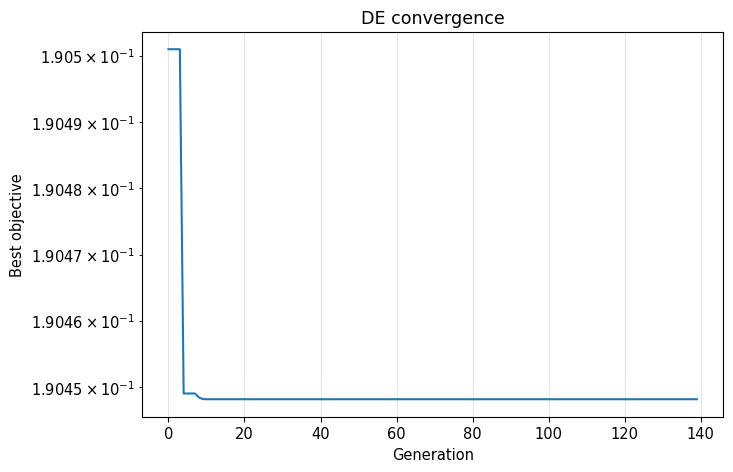

In [21]:
# 4. DE
de1 = differential_evolution_manual(objective1, bounds1, pop_size=70, generations=140, F=.7, CR=.9, seed=12)
print('DE:',de1['x'],'J=',de1['fun'],'nfev=',de1['nfev']);

plt.plot(de1['history']);
plt.yscale('log');
plt.xlabel('Generation');
plt.ylabel('Best objective');
plt.title('DE convergence');
plt.grid(alpha=.3);
plt.show()

## 2.4 GA & DE Repeatability Analysis

In [22]:
# 5. Repeatability Study
records = []
for seed in range(8):
    a = genetic_algorithm(objective1, bounds1, pop_size=40, generations=60, seed=1000+seed)
    b = differential_evolution_manual(objective1, bounds1, pop_size=40, generations=60, seed=2000+seed)
    records += [['GA', seed, a['fun'], a['nfev']], ['DE', seed, b['fun'], b['nfev']]]
R = pd.DataFrame(records, columns=['Method', 'Seed', 'Objective', 'Evaluations'])
display(R.groupby('Method')['Objective'].agg(['mean', 'std', 'min', 'max']))

,mean,std,min,max
Method,,,,
DE,0.190448,0.000000e+00,0.190448,0.190448
GA,0.190448,2.052167e-10,0.190448,0.190448


## 2.5 Methods Comparison

In [24]:
display(pd.DataFrame([['Gradient (best start)',
                       bestlocal1['k*'],bestlocal1['c*'],bestlocal1['J*'],bestlocal1['nfev']],
                        ['GA',*ga1['x'],ga1['fun'],ga1['nfev']],
                         ['DE',*de1['x'],de1['fun'],de1['nfev']]],
                     columns=['Method','k','c','Objective','Evaluations']).round(5))

,Method,k,c,Objective,Evaluations
0,Gradient (best start),43124.63546,349.74306,0.20726,21
1,GA,45000.00000,317.01412,0.19045,9870
2,DE,45000.00000,317.01412,0.19045,9870


# 3. Problem 2 — Constrained vibration-isolator design
For a machine on a spring-damper support,
$$
\omega_n=\sqrt{k/m},\quad\zeta=\frac{c}{2\sqrt{km}},\quad r=\frac{\omega}{\omega_n},
$$
and force transmissibility is
$$
T_R=\frac{\sqrt{1+(2\zeta r)^2}}{\sqrt{(1-r^2)^2+(2\zeta r)^2}}.
$$
Static deflection is $\delta_s=mg/k$.

Minimize normalized support cost
$$
C(k,c)=0.65\frac{k}{40000}+0.35\frac{c}{1200}
$$
subject to
$$
T_R\le0.24,\qquad\delta_s\le0.030\ \mathrm m,\qquad\zeta\ge0.04.
$$
Use $m=45$ kg, $\omega=55$ rad/s, $15000\le k\le120000$, and $80\le c\le3000$.

SLSQP receives the constraints explicitly; GA and DE use the same quadratic exterior penalty.

## Tasks
1. Implement all vibration quantities, cost, and $g_j\le0$ constraints.
2. Inspect the feasible region.
3. Solve with SLSQP.
4. Solve with GA and DE using the same penalty.
5. Verify the original constraints.
6. Repeat GA/DE with several seeds.
7. Test a smaller and larger \(
ho\) and explain the effect.

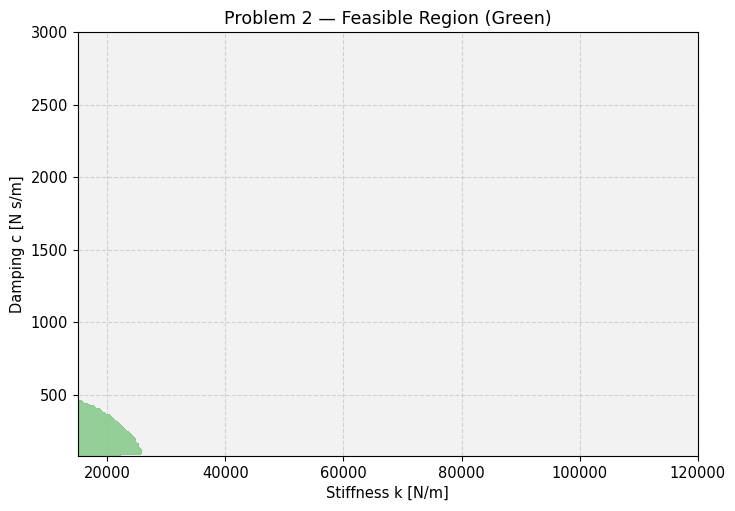

In [25]:
m2=45.; omega2=55.; grav=9.81; bounds2=[(15000.,120000.),(80.,3000.)]

def vib2(x):
    k, c = x
    wn = np.sqrt(k / m2)
    zeta = c / (2.0 * np.sqrt(k * m2))
    r = omega2 / wn
    TR = np.sqrt(1.0 + (2.0 * zeta * r)**2) / np.sqrt((1.0 - r**2)**2 + (2.0 * zeta * r)**2)
    delta = m2 * grav / k
    return wn, zeta, r, TR, delta

def objective2(x):
    k, c = x
    return 0.65 * (k / 40000.0) + 0.35 * (c / 1200.0)

def constraints2(x):
    wn, zeta, r, TR, delta = vib2(x)
    return np.array([TR - 0.24, delta - 0.030, 0.04 - zeta])

# Visual illustration aiming at inspecting the feasible region
K_vals = np.linspace(15000, 120000, 200)
C_vals = np.linspace(80, 3000, 150)
KK, CC = np.meshgrid(K_vals, C_vals)
feasibility_grid = np.array([[np.all(constraints2([k, c]) <= 0) for k in K_vals] for c in C_vals])

plt.figure(figsize=(8, 5.5))
plt.contourf(KK, CC, feasibility_grid.astype(float), levels=[-0.5, 0.5, 1.5], colors=['#eaeaea', '#4caf50'], alpha=0.6)
plt.xlabel('Stiffness k [N/m]')
plt.ylabel('Damping c [N s/m]')
plt.title('Problem 2 — Feasible Region (Green)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 3.1 SLSQP solution
SLSQP receives the physical constraints explicitly, avoiding a penalty parameter for the local solution.

In [29]:
# 1. SLSQP Solution
r2 = minimize(objective2, [40000, 800], method='SLSQP', bounds=bounds2, constraints={'type': 'ineq', 'fun': lambda x: -constraints2(x)}, options={'ftol': 1e-12, 'maxiter': 1000})
print('SLSQP Solution:')
print(f"  k* = {r2.x[0]:.2f}, c* = {r2.x[1]:.2f}, Cost = {r2.fun:.5f}")
print(f"  Constraints g(x) = {constraints2(r2.x)}")
print(f"  Evaluations: {r2.nfev}")

SLSQP Solution:
  k* = 15000.00, c* = 80.00, Cost = 0.26708
  Constraints g(x) = [-0.11102816 -0.00057    -0.00868645]
  Evaluations: 72


## 3.2 GA with quadratic exterior penalty

In [31]:
# 2. GA with quadratic exterior penalty (rho = 1e7)
ga2 = genetic_algorithm(objective2, bounds2, constraints2, pop_size=80, generations=160, mutation_rate=.18, mutation_scale=.06, rho=1e7, seed=21)

print('GA Solution (rho=1e7):')
print(f"  k* = {ga2['x'][0]:.2f}, c* = {ga2['x'][1]:.2f}, Cost = {ga2['fun']:.5f}")
print(f"  Constraints g(x) = {constraints2(ga2['x'])}")
print(f"  Evaluations: {ga2['nfev']}")

GA Solution (rho=1e7):
  k* = 15000.00, c* = 80.00, Cost = 0.26708
  Constraints g(x) = [-0.11102816 -0.00057    -0.00868645]
  Evaluations: 12880


In [33]:
# 3. Sensitivity Analysis for Penalty Coefficient rho
rhos = [1e3, 1e5, 1e7, 1e9]
results = []
for r_val in rhos:
    # Run DE with current rho value
    sol_ga2 = genetic_algorithm(objective2, bounds2, constraints2, pop_size=80, generations=160, mutation_rate=.18, mutation_scale=.06, rho=r_val, seed=21)
    max_ga2 = np.max(constraints2(sol_ga2['x']))
    results.append([r_val, sol_ga2['x'][0], sol_ga2['x'][1], sol_ga2['fun'], max_ga2, sol_ga2['nfev']])

df_sens_ga2 = pd.DataFrame(results, columns=['rho', 'k*', 'c*', 'Objective Cost', 'Max Constraint Violation', 'Evaluations'])
print('Penalty Coefficient Sensitivity Study:')
display(df_sens_ga2.round(6))

Penalty Coefficient Sensitivity Study:


,rho,k*,c*,Objective Cost,Max Constraint Violation,Evaluations
0,1.000000e+03,15000.0,80.0,0.267083,-0.00057,12880
1,1.000000e+05,15000.0,80.0,0.267083,-0.00057,12880
2,1.000000e+07,15000.0,80.0,0.267083,-0.00057,12880
3,1.000000e+09,15000.0,80.0,0.267083,-0.00057,12880


## 3.3 DE with quadratic exterior penalty

In [34]:
# 4. DE with quadratic exterior penalty (rho = 1e7)
de2 = differential_evolution_manual(objective2, bounds2, constraints2, pop_size=80, generations=160, F=.7, CR=.9, rho=1e7, seed=22)

print('DE Solution (rho=1e7):')
print(f"  k* = {de2['x'][0]:.2f}, c* = {de2['x'][1]:.2f}, Cost = {de2['fun']:.5f}")
print(f"  Constraints g(x) = {constraints2(de2['x'])}")
print(f"  Evaluations: {de2['nfev']}")

DE Solution (rho=1e7):
  k* = 15000.00, c* = 80.00, Cost = 0.26708
  Constraints g(x) = [-0.11102816 -0.00057    -0.00868645]
  Evaluations: 12880


In [35]:
# 5. Sensitivity Analysis for Penalty Coefficient rho
rhos = [1e3, 1e5, 1e7, 1e9]
results = []
for r_val in rhos:
    # Run DE with current rho value
    sol = differential_evolution_manual(objective2, bounds2, constraints2, pop_size=80, generations=160, F=.7, CR=.9, rho=r_val, seed=22)
    max_g = np.max(constraints2(sol['x']))
    results.append([r_val, sol['x'][0], sol['x'][1], sol['fun'], max_g, sol['nfev']])

df_sens = pd.DataFrame(results, columns=['rho', 'k*', 'c*', 'Objective Cost', 'Max Constraint Violation', 'Evaluations'])
print('Penalty Coefficient Sensitivity Study:')
display(df_sens.round(6))

Penalty Coefficient Sensitivity Study:


,rho,k*,c*,Objective Cost,Max Constraint Violation,Evaluations
0,1.000000e+03,15000.0,80.0,0.267083,-0.00057,12880
1,1.000000e+05,15000.0,80.0,0.267083,-0.00057,12880
2,1.000000e+07,15000.0,80.0,0.267083,-0.00057,12880
3,1.000000e+09,15000.0,80.0,0.267083,-0.00057,12880


## 3.4 Methods Comparison

In [36]:
display(pd.DataFrame([['SLSQP',*r2.x,r2.fun,r2.nfev,np.max(constraints2(r2.x))],
 ['GA',*ga2['x'],ga2['fun'],ga2['nfev'],np.max(constraints2(ga2['x']))],
  ['DE',*de2['x'],de2['fun'],de2['nfev'],np.max(constraints2(de2['x']))]],
                     columns=['Method','k','c','Cost','Evaluations','max g']).round(6))

,Method,k,c,Cost,Evaluations,max g
0,SLSQP,15000.0,80.0,0.267083,72,-0.00057
1,GA,15000.0,80.0,0.267083,12880,-0.00057
2,DE,15000.0,80.0,0.267083,12880,-0.00057


# 4. Problem 3 — Multiobjective vibration-isolator design
Use the same isolator at $\Omega=[45,55,65]$ rad/s. Minimize two competing objectives:
$$
f_1(k,c)=\sqrt{\frac{1}{3}\sum_iT_R(k,c;\Omega_i)^2}
$$
and
$$
f_2(k,c)=0.65\frac{k}{40000}+0.35\frac{c}{1200}.
$$
Constraints are $mg/k\le0.030$ m and $\zeta\ge0.03$.

A design is Pareto efficient if no other feasible design improves one objective without worsening another. To compare all three solvers using the same machinery, normalize the objectives and repeatedly solve
$$
J_w=w\hat f_1+(1-w)\hat f_2,\qquad0\le w\le1.
$$
The nondominated solutions approximate the Pareto front. Dedicated methods such as NSGA-II are a natural extension, but weighted scalarization keeps this introductory comparison controlled.

## Tasks
1. Implement both objectives and constraints.
2. Generate a feasible random sample and determine normalization ranges.
3. Define 9–11 scalarization weights.
4. Solve every weight with SLSQP, GA, and DE.
5. Implement Pareto dominance filtering.
6. Plot approximate fronts.
7. Identify vibration-priority, cost-priority, and compromise designs.
8. Explain why weighted sums are useful here and why they are not the only multiobjective approach.

In [37]:
m3 = 45.0
omegas3 = np.array([45.0, 55.0, 65.0])
bounds3 = [(15000.0, 120000.0), (80.0, 3000.0)]

def TR3(x, omega_val):
    k, c = x
    wn = np.sqrt(k / m3)
    zeta = c / (2.0 * np.sqrt(k * m3))
    r = omega_val / wn
    return np.sqrt(1.0 + (2.0 * zeta * r)**2) / np.sqrt((1.0 - r**2)**2 + (2.0 * zeta * r)**2)

def objectives3(x):
    k, c = x
    f1 = np.sqrt(np.mean(np.array([TR3(x, w) for w in omegas3])**2))
    f2 = 0.65 * (k / 40000.0) + 0.35 * (c / 1200.0)
    return np.array([f1, f2])

def constraints3(x):
    k, c = x
    wn = np.sqrt(k / m3)
    zeta = c / (2.0 * np.sqrt(k * m3))
    delta = m3 * 9.81 / k
    return np.array([delta - 0.030, 0.03 - zeta])

def nondominated_mask(F):
    F = np.asarray(F)
    keep = np.ones(len(F), dtype=bool)
    for i in range(len(F)):
        if np.any(np.all(F <= F[i], axis=1) & np.any(F < F[i], axis=1)):
            keep[i] = False
    return keep

In [38]:
# Generate a random sample of the design space to normalize objective functions
rng = np.random.default_rng(30)
raw_sample = rng.uniform([15000.0, 80.0], [120000.0, 3000.0], size=(12000, 2))

# Keep only those samples that satisfy the constraints3(x) <= 0
feasible_mask = np.array([np.all(constraints3(x) <= 0) for x in raw_sample])
S = raw_sample[feasible_mask]

# Evaluate objectives on the feasible sample to determine min and max boundaries
FS = np.array([objectives3(x) for x in S])
fmin3 = FS.min(0)
fmax3 = FS.max(0)

# Define the scalarized weighted-sum objective with normalization
def scalar3(x, w):
    # Normalize objectives into [0, 1] range
    f_vals = objectives3(x)
    fn = (f_vals - fmin3) / (fmax3 - fmin3)
    return w * fn[0] + (1.0 - w) * fn[1]

# Define 9 scalarization weights
weights3 = np.linspace(0.05, 0.95, 9)

print("Initialization and normalization ranges completed:")
print(f"Feasible samples: {len(S)} / 12000")
print(f"fmin3 (normalization min): {fmin3}")
print(f"fmax3 (normalization max): {fmax3}")
print(f"Weights: {weights3}")

Initialization and normalization ranges completed:
Feasible samples: 11894 / 12000
fmin3 (normalization min): [0.15920255 0.28667005]
fmax3 (normalization max): [9.36044796 2.80638045]
Weights: [0.05   0.1625 0.275  0.3875 0.5    0.6125 0.725  0.8375 0.95  ]


## 4.1 Gradient-based weighted-sum solutions

In [ ]:
# 1. Run SLSQP for each scalarized weight
LP = []
for w in weights3:
    r = minimize(lambda x, w=w: scalar3(x, w), [40000.0, 700.0], method='SLSQP', bounds=bounds3,
                 constraints={'type': 'ineq', 'fun': lambda x: -constraints3(x)},
                 options={'maxiter': 700, 'ftol': 1e-10})
    LP.append([w, *r.x, *objectives3(r.x), r.nfev])
LP = np.array(LP)

In [43]:
df_LP = pd.DataFrame(LP, columns=['weight','k*', 'c*', 'Objective 1', 'Objective 2', 'Evaluations'])
print('Gradient-based solutions:')
display(df_LP.round(6))

Gradient-based solutions:


,weight,k*,c*,Objective 1,Objective 2,Evaluations
0,0.0500,39965.303732,80.463527,0.534990,0.672905,39.0
1,0.1625,39964.877203,80.463098,0.534980,0.672898,39.0
2,0.2750,39964.335875,80.462553,0.534968,0.672889,43.0
3,0.3875,39963.632161,80.461844,0.534953,0.672877,39.0
4,0.5000,39962.732989,80.460939,0.534933,0.672862,43.0
5,0.6125,39961.466903,80.459665,0.534905,0.672841,39.0
6,0.7250,39959.610691,80.457796,0.534864,0.672811,42.0
7,0.8375,39956.736223,80.454902,0.534800,0.672763,42.0
8,0.9500,39951.359516,80.449489,0.534681,0.672674,42.0


## 4.2 GA weighted-sum solutions

In [ ]:
# 2. Run GA for each scalarized weight
GP = []
for j, w in enumerate(weights3):
    r = genetic_algorithm(lambda x, w=w: scalar3(x, w), bounds3, constraints3, pop_size=45, generations=70, rho=1e7, seed=100 + j)
    GP.append([w, *r['x'], *objectives3(r['x']), r['nfev']])
GP = np.array(GP)

In [45]:
df_GA = pd.DataFrame(GP, columns=['weight','k*', 'c*', 'Objective 1', 'Objective 2', 'Evaluations'])
print('GA solutions:')
display(df_GA.round(6))

GA solutions:


,weight,k*,c*,Objective 1,Objective 2,Evaluations
0,0.0500,15000.0,80.0,0.148117,0.267083,3195.0
1,0.1625,15000.0,80.0,0.148117,0.267083,3195.0
2,0.2750,15000.0,80.0,0.148117,0.267083,3195.0
3,0.3875,15000.0,80.0,0.148117,0.267083,3195.0
4,0.5000,15000.0,80.0,0.148117,0.267083,3195.0
5,0.6125,15000.0,80.0,0.148117,0.267083,3195.0
6,0.7250,15000.0,80.0,0.148117,0.267083,3195.0
7,0.8375,15000.0,80.0,0.148117,0.267083,3195.0
8,0.9500,15000.0,80.0,0.148117,0.267083,3195.0


## 4.3 DE weighted-sum solutions

In [ ]:
# 3. Run DE for each scalarized weight
DP = []
for j, w in enumerate(weights3):
    r = differential_evolution_manual(lambda x, w=w: scalar3(x, w), bounds3, constraints3, pop_size=45, generations=70, F=0.7, CR=0.9, rho=1e7, seed=200 + j)
    DP.append([w, *r['x'], *objectives3(r['x']), r['nfev']])
DP = np.array(DP)

In [46]:
df_DE = pd.DataFrame(DP, columns=['weight','k*', 'c*', 'Objective 1', 'Objective 2', 'Evaluations'])
print('DE solutions:')
display(df_DE.round(6))

DE solutions:


,weight,k*,c*,Objective 1,Objective 2,Evaluations
0,0.0500,15000.0,80.0,0.148117,0.267083,3195.0
1,0.1625,15000.0,80.0,0.148117,0.267083,3195.0
2,0.2750,15000.0,80.0,0.148117,0.267083,3195.0
3,0.3875,15000.0,80.0,0.148117,0.267083,3195.0
4,0.5000,15000.0,80.0,0.148117,0.267083,3195.0
5,0.6125,15000.0,80.0,0.148117,0.267083,3195.0
6,0.7250,15000.0,80.0,0.148117,0.267083,3195.0
7,0.8375,15000.0,80.0,0.148117,0.267083,3195.0
8,0.9500,15000.0,80.0,0.148117,0.267083,3195.0


## 4.4 Methods comparison and nondominance filtering

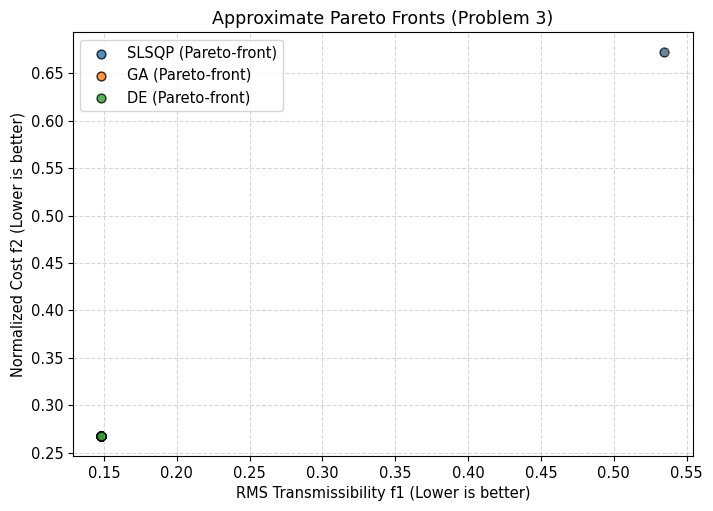

In [39]:
# 4. Plot the approximate fronts using the non-dominated mask
plt.figure(figsize=(8, 5.5))
for A_arr, label in [(LP, 'SLSQP'), (GP, 'GA'), (DP, 'DE')]:
    mask = nondominated_mask(A_arr[:, 3:5])
    plt.scatter(A_arr[mask, 3], A_arr[mask, 4], label=f"{label} (Pareto-front)", s=40, edgecolors='k', alpha=0.8)
    # Plot dominated ones as faint markers for visibility
    plt.scatter(A_arr[~mask, 3], A_arr[~mask, 4], alpha=0.15, s=20, marker='x', color='gray')

plt.xlabel('RMS Transmissibility f1 (Lower is better)')
plt.ylabel('Normalized Cost f2 (Lower is better)')
plt.title('Approximate Pareto Fronts (Problem 3)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

# 5. Comparison and engineering interpretation

| Feature | Gradient-based | GA | DE |
|---|---|---|---|
| Search character | Local | Population heuristic | Population heuristic |
| Derivatives/local smoothness | Exploited | Not required | Not required |
| Primary operators | Search direction/line step | Selection, crossover, mutation | Difference mutation, crossover, greedy selection |
| Function evaluations | Usually fewer | Usually many | Usually many |
| Initial-condition sensitivity | Starting point | Population/seed | Population/seed |
| Multimodal exploration | Limited without multistart | Stronger | Stronger |
| Continuous variables | Very effective | Real-coded GA works naturally | Particularly natural |
| Constraint handling here | Native SLSQP | Penalty | Penalty |
| Local precision | Usually high | Can benefit from polishing | Can benefit from polishing |

A useful practical strategy is
$$
\boxed{\text{GA/DE global exploration}\to\text{gradient-based local polishing}}.
$$
The methods are therefore complementary rather than mutually exclusive.

# 6. Main takeaways
1. Gradient-based optimization is efficient when smooth local information is trustworthy.
2. GA maintains diversity through population selection, recombination, and mutation.
3. DE uses scaled differences between population members to create self-scaled continuous search steps.
4. Heuristic optimization does not eliminate formulation issues: bounds, scaling, penalties, and constraints remain critical.
5. Stochastic algorithms require repeated runs for meaningful comparison.
6. Multiobjective design produces a family of tradeoff solutions rather than a single universal optimum.
7. Hybrid global-local optimization is often an effective engineering workflow.

A natural follow-on topic is **NSGA-II** for direct multiobjective evolutionary optimization and surrogate-assisted GA/DE for expensive simulations.